## TRABAJO SOFTWARE MATEMÁTICO Y ESTADISTICO - Ane

El paquete `PaqueteAne` contiene diferentes funciones desarrolladas para la asignatura de Software Matemático y Estadístico.

El paquete incluye funciones para:

- discretización de variables
- cálculo de métricas
- normalización y estandarización
- filtrado de variables
- cálculo de correlaciones e información mutua
- representación gráfica de curvas ROC y matrices de correlación.

El primer paso es leer las funciones utilizadas a lo largo de los ejercicios de la asignatura. Por cuestión de orden, todas ellas se han agrupado en un único fichero llamado *Funciones.py*. Para poder ejecutar y replicar correctamente el contenido de este documento, es necesario que tanto el fichero *Funciones.R* como este documento se encuentren en el mismo directorio.

In [2]:
from Funciones import *

## Algoritmos de discretización

En este documento se explicarán diferentes algoritmos de discretización. La discretización consiste en transformar una variable numérica continua en una variable categórica, agrupando sus valores en un número determinado de intervalos. Este proceso permite simplificar la representación de los datos y puede facilitar su análisis e interpretación, especialmente cuando se trabaja con métodos que requieren variables categóricas.

Existen diferentes estrategias para determinar cómo se realizan estas agrupaciones. Entre los métodos clásicos se encuentran *Equal Width* (EW) y *Equal Frequency* (EF). El primero divide el rango de valores en intervalos de igual amplitud, mientras que el segundo busca que los intervalos contengan aproximadamente el mismo número de observaciones. También existen métodos basados en otros criterios, como la entropía, que permiten determinar los puntos de corte teniendo en cuenta la distribución de los datos y, en determinados casos, la información de la variable objetivo.

A continuación, se analizarán dichas funciones, explicando su funcionamiento y mostrando sus principales diferencias mediante ejemplos. 


**Discretize**

La función *Discretize* permite realizar una discretización a partir de unos puntos de corte definidos previamente. En este caso, el usuario define puntos de corte que se utilizan para discretizar la lista de puntos. La función recibe un vector numérico y una lista de puntos de corte, y devuelve un vector categórico en el que cada valor queda asignado al intervalo correspondiente:

In [3]:
x=[1,10,2,9,78,2,19,80,91]
puntos_corte=[2,80,60,90]
discretize(x,puntos_corte)

['I1', 'I2', 'I1', 'I2', 'I3', 'I1', 'I2', 'I3', 'I5']
Categories (5, str): ['I1' < 'I2' < 'I3' < 'I4' < 'I5']

Tal y como se observa, la función crea $(n+1)$ grupos o niveles, siendo $(n)$ la longitud del vector puntos.corte. En este caso concreto, se generan cinco grupos. El primer grupo, (I1), comprende el intervalo $(-∞, 2])$, incluyendo también el valor 2. El segundo grupo comprende los valores mayores que 2 y menores o iguales que 60, el tercero los valores mayores que 60 y menores o iguales que 80, y el cuarto los valores mayores que 80 y menores o iguales que 90. Finalmente, se crea un último grupo que comprende los valores superiores a 90. Así, cada valor de **x** queda asignado a una categoría en función del intervalo en el que se encuentra.

También se puede emplear esta función en datasets completos. Para ello, hay que llamar a la función *discretize.dataset()* y las variables siguen siendo los datos y los puntos de corte. 

In [4]:
datos = pd.DataFrame({
    "v1": [1, 10, 2, 9, 78, 2, 19, 80, 91],
    "v2": [10, 2, 291, 23, 86, 52, 39, 18, 29],
    "v3": [1.60, 1.70, 1.75, 1.80, 1.90, 2, 1.78, 9.23, 100]
})

puntos_corte = [2,80,60,90]
discretize_dataset(datos,puntos_corte)

,v1,v2,v3
0,I1,I2,I1
1,I2,I1,I1
2,I1,I5,I1
3,I2,I2,I1
4,I3,I4,I1
5,I1,I2,I1
6,I2,I2,I1
7,I3,I2,I2
8,I5,I2,I5



**Discretize Equal Width**

Tal y como se ha mencionado, uno de los algorítmos clásicos es *Equal Width*. Dado un vector de números reales y un número de intervalos, este algoritmo determina los puntos de corte necesarios para generar un vector categórico de tal manera que esos puntos estén uniformemente distribuidos en el rango de los valores. 

Como se ve en el ejemplo, si se tienen los valores (11.5, 10.2, 1.2, 0.5, 5.3, 20.5, 8.4) y se quiere generar una variable categórica con 4 posibles valores, es necesario determinar cuatro puntos de corte, que serán valores que separen el intervalo (entre 0.5 y 20.5 en este caso) en 4 tramos de igual tamaño. En este caso, cada intervalo tendrá una amplitud de 5. Por tanto, los intervalos serán: de 0.5 a 5.5, de 5.5 a 10.5, de 10.5 a 15.5 y de 15.5 a 20.5. De esta forma, se obtienen 3 puntos de corte: 5.5, 10.5 y 15.5.

Cuando se aplica este procedimiento a nuevos valores, estos pueden encontrarse fuera del rango de los datos utilizados originalmente para determinar los puntos de corte. Para poder asignar estos valores a algún intervalo, se considera que el primer intervalo se extiende hasta (-∞) y que el último se extiende hasta (+∞). Por tanto, una vez aplicado el algoritmo, el resultado puede representarse mediante un vector categórico como el siguiente: (I3, I2, I1, I1, I4, I2), donde:
I1=(-∞, 5.5], I2=(5.5, 10.5], I3=(10.5, 15.5], I4=(15.5, ∞).


Por lo tanto, se a creado una función *discretizeEW()* que recibe como entrada un vector de tipo numérico y un número de intervalos:


In [5]:
x2 =[11.5,10.2,1.2,0.5,5.5,20.5,8.4]
num_int = 4
discretizeEW(x2,num_int)

{'valores': ['I3', 'I2', 'I1', 'I1', 'I2', 'I4', 'I2']
 Categories (4, str): ['I1' < 'I2' < 'I3' < 'I4'],
 'intervalos': ['I1 = (-Inf,5.5]',
  'I2 = (5.5,10.5]',
  'I3 = (10.5,15.5]',
  'I4 = (15.5,Inf]'],
 'puntos de corte': 'Puntos de corte: 5.5, 10.5, 15.5'}

Como resultado, la función devuelve un vector de valores categóricos que indica a qué intervalo pertenece cada valor, así como los puntos de corte obtenidos. Estos puntos de corte pueden utilizarse posteriormente para discretizar nuevos valores utilizando los mismos intervalos. Además, para mejorar la legibilidad del resultado, se indican los límites correspondientes a cada intervalo.

Si se quiere aplicar esta función a un dataset, podemos usar la función *discretizeEW.dataset()*. Esta función funciona exactamente igual que el anterior, recorriendo las columnas una a una. 

In [6]:
datos =pd.DataFrame({
  "v1": [11.5,10.2,1.2,0.5,5.5,20.5,8.4],
  "v2": [1000,1500,2000,2500,3000,2800,4000],
  "v3": [1.60,1.70,1.75,1.80,1.90,2,1.78]})
num_int = 4
discretizeEW_dataset(datos,num_int)

,v1,v2,v3
0,I3,I1,I1
1,I2,I1,I1
2,I1,I2,I2
3,I1,I3,I3
4,I2,I3,I4
5,I4,I3,I4
6,I2,I4,I2



**Discretize Equal Frequency**

Otro de los algoritmos clásicos es *Equal Frequency*. En este caso, el objetivo es buscar los puntos de corte que hagan que el número de valores del vector a discretizar que caen en cada uno de los intervalos sea el mismo. En caso de que el número de valores no sea divisible entre el número de intervalos, algunos grupos pueden contener un elemento más o menos que otros.

Por ejemplo, si tenemos un vector de 9 elementos y queremos dividirlo en 3 grupos, el algoritmo *Equal Frequency* formará 3 grupos de 3 elementos. Para ello, primero se ordenan los valores del vector y, posteriormente, se asigna cada valor al grupo que le corresponde según su posición en el vector ordenado.

Para llevar a cabo este algoritmo, se ha creado una función *discretizeEF()*, que dado un vector de números y el número de grupos, devuelve los elementos discretizados y los elementos que forman cada grupo. 

In [7]:
x =[2,19,28,12,10,4,7,10,22]
num_grupos = 3
discretizeEF(x,num_grupos)

{'valores': ['I1', 'I3', 'I3', 'I2', 'I2', 'I1', 'I1', 'I2', 'I3']
 Categories (3, str): ['I1' < 'I2' < 'I3'],
 'grupos': ['I1=(2, 4, 7)', 'I2=(10, 10, 12)', 'I3=(19, 22, 28)']}

Sin embargo, cuando el número de elementos del vector no es divisible entre el número de grupos, no es posible que todos los grupos tengan exactamente el mismo número de elementos. En este caso, la función se encarga de distribuir los elementos restantes entre los grupos de forma que sus tamaños sean lo más similares posible. Esto se puede observar en el siguiente ejemplo:

In [8]:
x =[20,3,1,29,10,87,21]
num_grupos=5
discretizeEF(x,num_grupos)

{'valores': ['I4', 'I2', 'I1', 'I5', 'I3', 'I5', 'I4']
 Categories (5, str): ['I1' < 'I2' < 'I3' < 'I4' < 'I5'],
 'grupos': ['I1=(1)', 'I2=(3)', 'I3=(10)', 'I4=(20, 21)', 'I5=(29, 87)']}

Igual que se ha hecho en *Discretize Equal Width*, se ha creado una función adicional para los datasets: *discretizeEF.dataset()*.

In [9]:
datos = pd.DataFrame({
  "v1" : [20,3,1,29,10,87,21],
  "v2" : [1000,1500,2000,2500,3000,2800,4000],
  "v3" : [1.60,1.70,1.75,1.80,1.90,2,1.78]
})
num_grupos = 5
discretizeEF_dataset(datos,num_grupos)

,v1,v2,v3
0,I4,I1,I1
1,I2,I2,I2
2,I1,I3,I3
3,I5,I4,I4
4,I3,I5,I5
5,I5,I4,I5
6,I4,I5,I4


## Cálculo de métricas para los atributos de un dataset.

Las métricas permiten obtener información sobre las características y el comportamiento de los atributos de un conjunto de datos. Dependiendo del tipo de atributo, pueden utilizarse diferentes medidas para analizar su variabilidad, su capacidad de discriminación o la distribución de sus valores.

En este trabajo se implementa una función capaz de identificar el tipo de atributo y seleccionar automáticamente la métrica correspondiente. Para los atributos continuos o numéricos se calcula la varianza y el AUC (Area Under the Curve). Por otro lado, para los atributos discretos o categóricos se calcula la entropía, una medida que permite cuantificar el grado de incertidumbre o diversidad existente en la distribución de las categorías del atributo. 

Como ejemplo, vemos que proporcionando a la función *calcular_metricas()* el dataframe y el nombre de la columna donde están las etiquetas reales (para calcular el AUC), nos devuelve la varianza y la media de aquellas columnas numéricas, y la entropía de las columnas discretizadas tipo factor.

In [10]:
datos = pd.DataFrame({
    "edad": [20, 25, 30, 35, 40, 45],
    "sueldo": [1000, 5000, 1000, 2000, 3000, 3500],
    "sexo": pd.Categorical(["H", "M", "H", "M", "M", "H"]),
    "clase": [True, False, False, False, True, False]
})

resultado = calcular_metricas(datos, "clase")
resultado

,variable,tipo,varianza,AUC,entropia
0,edad,continua,8.750000e+01,0.3750,NaN
1,sueldo,continua,2.441667e+06,0.3125,NaN
2,sexo,discreta,NaN,NaN,1.0


Esta función general (*calcular_metricas()*) llama a su vez a funciones auxiliares para calcular las diferentes métricas. 

La varianza permite medir la dispersión de los valores respecto a su media, y se calcula como: 

$$
\mathrm{Var}(X) = \frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar{x})^2
$$

El AUC por su parte, permite evaluar la capacidad de un atributo numérico para distinguir entre las dos clases de una variable objetivo binaria. Por este motivo, el cálculo del AUC requiere que el dataset sea supervisado y que se especifique previamente una variable clase binaria.

Para calcularlo, se consideran diferentes valores de corte de la variable numérica. Para cada corte se obtiene un punto de la curva ROC, formado por la tasa de verdaderos positivos (TPR) y la tasa de falsos positivos (FPR). Estos puntos permiten construir la curva ROC, que representa la capacidad de la variable para distinguir entre las dos clases.

Para obtener cada uno de estos puntos se ha implementado la función *calcular_punto_ROC()*, que compara las predicciones obtenidas para un determinado punto de corte con las etiquetas reales y calcula los valores de FPR y TPR correspondientes.

Una vez obtenidos los diferentes puntos de la curva ROC, se ordenan según el valor de FPR y se calcula el área bajo la curva. Para realizar esta integración se utiliza la función *integraOptimizada()*, que aplica la regla del trapecio entre los distintos puntos.

Finalmente, la función *AUC()* se encarga de integrar todo el procedimiento: genera los puntos de corte, obtiene para cada uno su correspondiente punto ROC mediante *calcular_punto_ROC()*, ordena los puntos y calcula el área bajo la curva utilizando *integraOptimizada()*. El resultado final es el valor del AUC para la variable analizada.

Por otro lado, la entropía es una medida que permite cuantificar la distribución de las variables discretizadas: cuanto más uniforme sea la distribución de los valores, mayor será la entropía. Para calcularlo se ha aplicado la función *entropy()* que calcula la entropía utilizando la siguiente fórmula:

$$
H(X)=-\sum_i p_i\log_2(p_i)
$$

donde $p_i$ es la probabilidad estimada para cada valor posible. 


## Normalización y estandarización de variables.

La normalización y la estandarización son técnicas de transformación de datos que permiten modificar la escala de las variables numéricas de un conjunto de datos. Estas técnicas son especialmente útiles cuando las variables presentan rangos o unidades de medida diferentes, ya que permiten trabajar con ellas en una escala comparable.

La normalización transforma los valores de una variable para situarlos, habitualmente, en un intervalo entre 0 y 1. Para ello, se utiliza el valor mínimo y máximo de la variable. De esta forma, el valor mínimo pasa a ser 0 y el máximo pasa a ser 1, manteniendo las proporciones relativas entre los demás valores.

Se ha creado una función *normalizar()* donde, pasándole una variable numérica, devuelve el vector normalizado:

In [11]:
v = [1,2,3,4,5,6]
normalizar(v)

array([0. , 0.2, 0.4, 0.6, 0.8, 1. ])

Por otro lado, la estandarización transforma una variable de manera que tenga una media igual a 0 y una desviación estándar igual a 1. Para ello, a cada valor se le resta la media de la variable y el resultado se divide entre su desviación estándar. A diferencia de la normalización, los valores estandarizados no están limitados a un intervalo concreto. Para estandarizar un vector numérico se ha creado la función *estandarizar()*, donde se observa que después de estandarizar, la media es 0 y la desviación estandar 1:

In [12]:
estandarizado= estandarizar(v)
print(estandarizado)
print("Media: %s  Desviación estándar: %s " %(np.mean(estandarizado),round(np.std(estandarizado,ddof=1),2)))

[-1.33630621 -0.80178373 -0.26726124  0.26726124  0.80178373  1.33630621]
Media: 0.0  Desviación estándar: 1.0 


En caso de trabajar con datasets, se han creado dos funciones que normalizan/estandarizan las variables numéricas de dicho dataset: *normalizar.dataset()* y *estandarizar.dataset()*.

In [13]:
df4 =pd.DataFrame({
  "C1":[1,2,5,2,7,1,29,10],
  "C2":[12,2,1,5,1,9,10,2],
  "C3":["a", "a", "a", "b","c","c","b","c"]
})
normalizar_dataset(df4)


,C1,C2,C3
0,0.000000,1.000000,a
1,0.035714,0.090909,a
2,0.142857,0.000000,a
3,0.035714,0.363636,b
4,0.214286,0.000000,c
5,0.000000,0.727273,c
6,1.000000,0.818182,b
7,0.321429,0.090909,c


In [14]:
estandarizar_dataset(df4)

,C1,C2,C3
0,-0.651409,1.512048,a
1,-0.545056,-0.728023,a
2,-0.225999,-0.952030,a
3,-0.545056,-0.056002,b
4,-0.013294,-0.952030,c
5,-0.651409,0.840027,c
6,2.326460,1.064034,b
7,0.305763,-0.728023,c



## Filtrado de variables

En base a las métricas utilizadas, se ha desarrollado una función donde, dada una dataset, se obtiene uno nuevo donde todas las variables cumplan con los requisitos indicados.  

Para ello, a la función hay que proporcionarle el dataset que tenga como columnas las siguientes métricas: varianza, AUC y entropia. Este dataset puede ser el que se obtiene con la función *calcular_metricas()*, por ejemplo. Además del dataset, la función recoge los requisitos de las variables, en el siguiente orden: varianza, AUC, entropía.
Así, la función queda como:

*calcular_metricas(dataset, umbral_varianza,umbral_auc, umbral_entropia)*

Como ejemplo, se utiliza el dataset obtenido en *calcular_metricas()* y se ponen los siguientes umbrales:

In [15]:
filtrado_variables(resultado, 70,0.34,0.5)


['edad', 'sexo']

## Cálculo de la correlación

La correlación permite cuantificar el grado de asociación entre pares de variables. Resulta útil para identificar la existencia de relaciones o dependencias entre las variables de un conjunto de datos, ya que el estudio de estas asociaciones permite detectar patrones entre variables y obtener una visión global de la estructura de los datos. Además, puede ser de utilidad para identificar variables que aportan información similar o, por el contrario, variables cuya información es independiente.

Para calcular la correlación entre los elementos de un dataset, se ha desarrollado una función llamada *cor_dataset()*. Esta función recoje un dataset y actúa adaptandose a la naturaleza de las variables: para las variables tipo númerica-numérica, calcula la correlacion de Pearson, definida como:

$$r = \frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}{\sqrt{\sum_{i=1}^{n}(x_i-\bar{x})^2 \sum_{i=1}^{n}(y_i-\bar{y})^2}}$$


Donde $\bar{x}$ y $\bar{y}$ son las medias de las variables cuya correlación se quiere obtener.

Por otro lado, para las categóricas, calcula la información mutua: 

$$
I(X,Y)=\sum_{x\in X}\sum_{y\in Y}P(x,y)\log\left(\frac{P(x,y)}{P(x)P(y)}\right)
$$

donde $P(x,y)$ representa la probabilidad conjunta de observar los valores $(x)$ e $(y)$, mientras que $P(x)$ y $(P(y)$ representan sus respectivas probabilidades marginales. Un valor de información mutua igual a cero indica independencia entre las variables, mientras que valores mayores indican una mayor dependencia entre ellas. 

Para los pares formados por una variable numérica y una variable categórica, la función devuelve el valor NA, ya que este tipo de combinación no se contempla en el cálculo definido.

Teniendo los siguientes datos y aplicando la función se obtiene como resultado una matriz simétrica. En el caso de las variables categóricas, la diagonal no tiene por qué tomar el valor 1, a diferencia de lo que ocurre con la correlación de una variable numérica consigo misma. Esto se debe a que la función utiliza la información mutua, por lo que $I(X,X)$ equivale a la entropía de $X$, y su valor depende de la distribución de las categorías, tal y como se ha explicado anteriormente. 



In [16]:
datos =pd.DataFrame({
  "edad": [20, 25, 30, 35, 40],
  "salario": [1000, 1500, 2000, 2500, 3000],
  "sexo":  pd.Categorical(["H", "H", "H", "M", "H"]),
  "ciudad": pd.Categorical(["Bilbao", "Donosti", "Bilbao", "Paris", "Iruñea"])
})

cor_dataset(datos)

,edad,salario,sexo,ciudad
edad,1.0,1.0,NaN,NaN
salario,1.0,1.0,NaN,NaN
sexo,NaN,NaN,0.500402,0.500402
ciudad,NaN,NaN,0.500402,1.332179



## Gráficas

Por último se han creado dos funciones que se encargan de graficar por una parte, la curva ROC, y por la otra, las matrices de correlación/información mutua. 

Para representar gráficamente la curva ROC, se ha creado una función denominada *grafica_ROC()*. Esta función recibe como entradas un vector numérico, que puede corresponder, por ejemplo, a una columna de un conjunto de datos, y un vector de etiquetas binarias (TRUE/FALSE) que indica la clase real de cada observación. A partir de estos datos, la función calcula los distintos puntos de la curva ROC para diferentes valores de corte y los representa gráficamente.

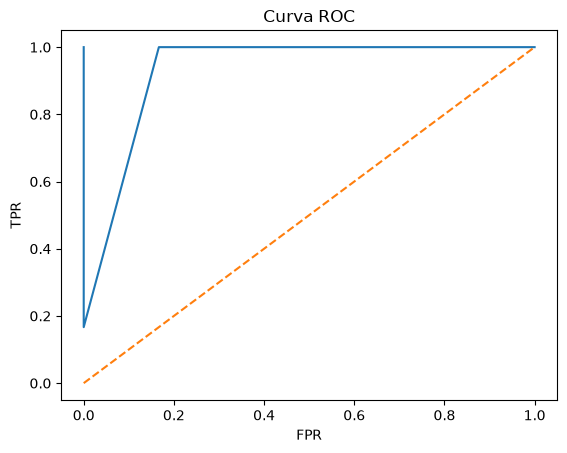

In [17]:
datos =pd.DataFrame({
  "valor" :[1.2, 1.5, 1.8, 2.0, 2.2, 2.5, 3.5, 3.8, 4.0, 4.3, 4.5, 5.0],
  "clase":[False, False, False, False, False, False,True, True, True, True, True, True]
})
grafica_ROC(datos["valor"],datos["clase"])


Para graficar la matriz de correlaciones, se ha creado la función *plot_correlaciones()* que recibe como entrada un dataset. A partir de este, calcula las medidas de asociación entre los pares de variables y las representa gráficamente, facilitando su interpretación y permitiendo identificar de forma visual las relaciones existentes entre las variables. Para implementar esta función se necesita tener instalado el paquete ggplot2. 

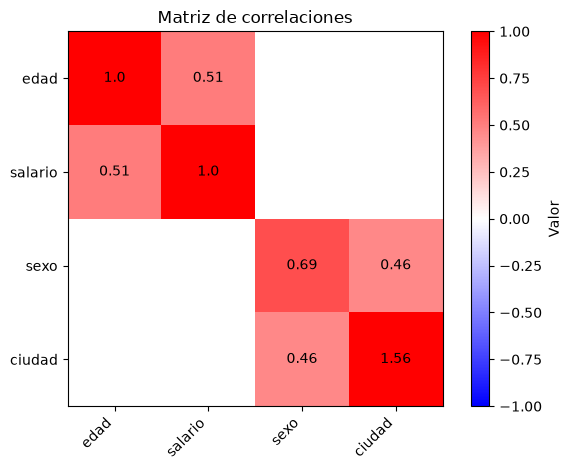

In [19]:
datos = pd.DataFrame({
  "edad" :[20, 50, 42, 67, 40,23],
  "salario" : [1500, 2500, 1500, 2500, 3000,2000],
  "sexo" : pd.Categorical(["H", "H", "M", "M", "H","M"]),
  "ciudad": ["Bilbao", "Donosti", "Bilbao", "Paris", "Iruñea","Elgoibar"]
  })

plot_correlaciones(datos)